In [69]:
import numpy as np
np.random.seed(42)

In [70]:
s = ('s1', 's2', 's3')

model = {
    'a11' : [(0, 0), (-1, 0.5), (-2, 0.5)],  # (reward, prob)
    'a12' : [(0, 0.5), (1, 0.25), (2, 0.25)],  # order: s1 s2 s3
    'a21' : [(1, 0.25), (0, 0.5), (-1, 0.25)],
    'a22' : [(-1, 1/6), (0, 2/3), (1, 1/6)],
    'a31' : [(2, 1/6), (1, 1/6), (0, 2/3)],
    'a32' : [(-2, 1/8), (-1, 1/8), (0, 3/4)]
}

terminal_reward = {'s1': -1, 's2': -8, 's3': -27}

policy_MD = {
    's1' : [('a11', 1), ('a12', 0)],  # (a, prob)
    's2' : [('a21', 1), ('a22', 0)],
    's3' : [('a31', 1), ('a32', 0)]
}

policy_MR = {
    's1' : [('a11', np.exp(-0.5)), ('a12', 1 - np.exp(-0.5))],  # (a, prob)
    's2' : [('a21', np.exp(-1)), ('a22', 1 - np.exp(-1))],
    's3' : [('a31', np.exp(-1.5)), ('a32', 1 - np.exp(-1.5))]
}

In [71]:
def evaluate(model, state, policy, N):
    reward = 0
    for i in range(N-1):
        d = policy.get(state)  
        a = np.random.choice([d[0][0], d[1][0]], p = [d[0][1], d[1][1]])
        tran_prob = model.get(a)
        new_state = np.random.choice([0, 1, 2], p = [tran_prob[0][1], tran_prob[1][1], tran_prob[2][1]])
        reward += model.get(a)[new_state][0]
        new_state = ['s1', 's2', 's3'][new_state]
        state = new_state
        if i == N - 2:
            reward += terminal_reward.get(state)       
    return reward

In [72]:
N = 2
iterations = 5000
E_policy_MD = np.zeros(3)
E_policy_MR = np.zeros(3)
init_state = ['s1', 's2', 's3']
reward_MD = np.zeros((3, iterations))
reward_MR = np.zeros((3, iterations))
for k in range(3):
    state = init_state[k]
    for i in range(iterations):
        reward_MD[k, i] = evaluate(model, state, policy_MD, N)
        reward_MR[k, i] = evaluate(model, state, policy_MR, N)
    E_policy_MD[k] = np.mean(reward_MD[k])
    E_policy_MR[k] = np.mean(reward_MR[k])
print("Expected reward for policy_MD: ", E_policy_MD)
print("Expected reward for policy_MR: ", E_policy_MR)

Expected reward for policy_MD:  [-19.032  -10.8168 -19.0488]
Expected reward for policy_MR:  [-14.9568 -10.356  -21.222 ]


In [73]:
reward_MD

array([[-29.,  -9., -29., ..., -29.,  -9.,  -9.],
       [  0.,  -8.,   0., ..., -28.,  -8.,  -8.],
       [  1.,  -7.,  -7., ...,   1., -27.,  -7.]])

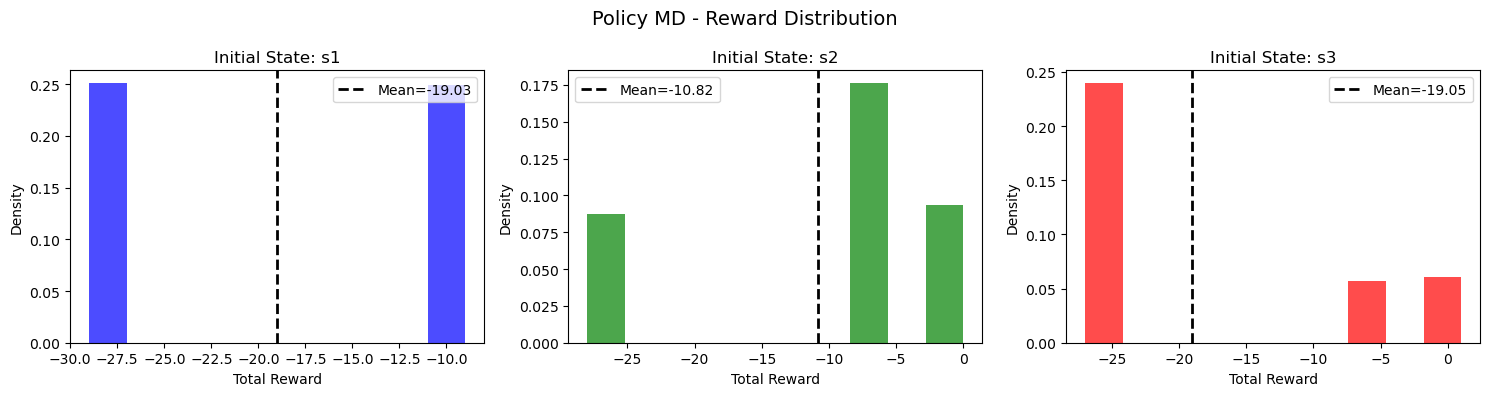

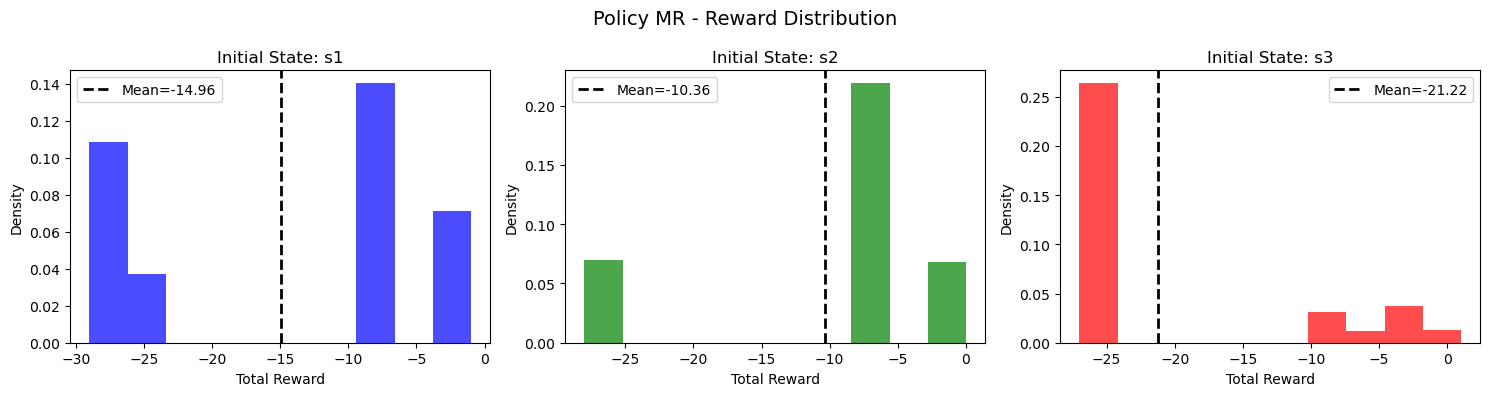

In [74]:
import matplotlib.pyplot as plt

# 第一张图：policy_MD
fig1, axes1 = plt.subplots(1, 3, figsize=(15, 4))
states = ['s1', 's2', 's3']
colors = ['blue', 'green', 'red']

for k in range(3):
    axes1[k].hist(reward_MD[k], bins=10, density=True, alpha=0.7, color=colors[k])
    axes1[k].axvline(E_policy_MD[k], color='black', linestyle='--', linewidth=2, label=f'Mean={E_policy_MD[k]:.2f}')
    axes1[k].set_title(f'Initial State: {states[k]}')
    axes1[k].set_xlabel('Total Reward')
    axes1[k].set_ylabel('Density')
    axes1[k].legend()

fig1.suptitle('Policy MD - Reward Distribution', fontsize=14)
plt.tight_layout()
plt.savefig('policy_MD_reward_distribution.png')
plt.show()

# 第二张图：policy_MR
fig2, axes2 = plt.subplots(1, 3, figsize=(15, 4))

for k in range(3):
    axes2[k].hist(reward_MR[k], bins=10, density=True, alpha=0.7, color=colors[k])
    axes2[k].axvline(E_policy_MR[k], color='black', linestyle='--', linewidth=2, label=f'Mean={E_policy_MR[k]:.2f}')
    axes2[k].set_title(f'Initial State: {states[k]}')
    axes2[k].set_xlabel('Total Reward')
    axes2[k].set_ylabel('Density')
    axes2[k].legend()

fig2.suptitle('Policy MR - Reward Distribution', fontsize=14)
plt.tight_layout()
plt.savefig('policy_MR_reward_distribution.png')
plt.show()

In [75]:
for name, reward in [('MD(π)', reward_MD), ('MR(π\')', reward_MR)]:
    print(f"\n=== {name} ===")
    for k, s in enumerate(['s1','s2','s3']):
        std = np.std(reward[k])          # 标准差
        p95 = np.percentile(reward[k], 95)  # 第95百分位
        mean = np.mean(reward[k])
        print(f"{s}: mean={mean:.2f}, std={std:.2f}, 95th percentile={p95:.2f}")


=== MD(π) ===
s1: mean=-19.03, std=10.00, 95th percentile=-9.00
s2: mean=-10.82, std=10.34, 95th percentile=0.00
s3: mean=-19.05, std=11.57, 95th percentile=1.00

=== MR(π') ===
s1: mean=-14.96, std=11.21, 95th percentile=-1.00
s2: mean=-10.36, std=8.58, 95th percentile=0.00
s3: mean=-21.22, std=9.87, 95th percentile=-3.00


In [76]:
def new_evaluate(model, state, policy, N, gamma):
    reward = 0
    for i in range(N-1):
        d = policy.get(state)  
        a = np.random.choice([d[0][0], d[1][0]], p = [d[0][1], d[1][1]])
        tran_prob = model.get(a)
        new_state = np.random.choice([0, 1, 2], p = [tran_prob[0][1], tran_prob[1][1], tran_prob[2][1]])
        reward += model.get(a)[new_state][0]
        new_state = ['s1', 's2', 's3'][new_state]
        state = new_state
        if i == N - 2:
            reward += terminal_reward.get(state)       
    return np.exp(gamma * reward)

In [77]:
N = 2
iterations = 5000
gamma = 0.9  # 这里只是举个例子
E_policy_MD = np.zeros(3)
E_policy_MR = np.zeros(3)
init_state = ['s1', 's2', 's3']
reward_MD = np.zeros((3, iterations))
reward_MR = np.zeros((3, iterations))
for k in range(3):
    state = init_state[k]
    for i in range(iterations):
        reward_MD[k, i] = new_evaluate(model, state, policy_MD, N, gamma)
        reward_MR[k, i] = new_evaluate(model, state, policy_MR, N, gamma)
    E_policy_MD[k] = np.mean(reward_MD[k])
    E_policy_MR[k] = np.mean(reward_MR[k])
print("Expected reward for policy_MD: ", E_policy_MD)
print("Expected reward for policy_MR: ", E_policy_MR)

Expected reward for policy_MD:  [1.51344617e-04 2.52771202e-01 4.09577275e-01]
Expected reward for policy_MR:  [0.07792518 0.10844322 0.11618112]


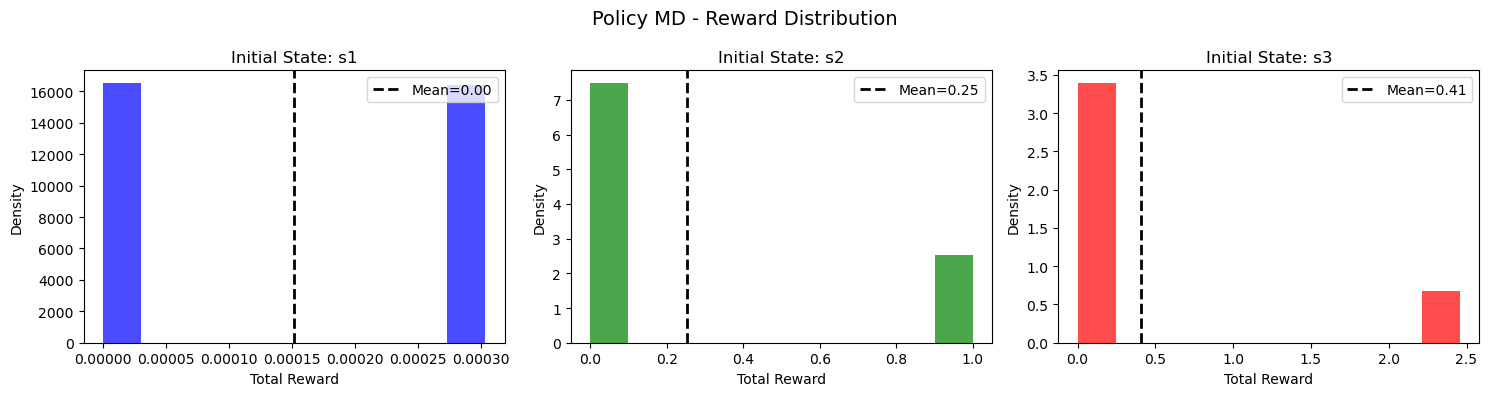

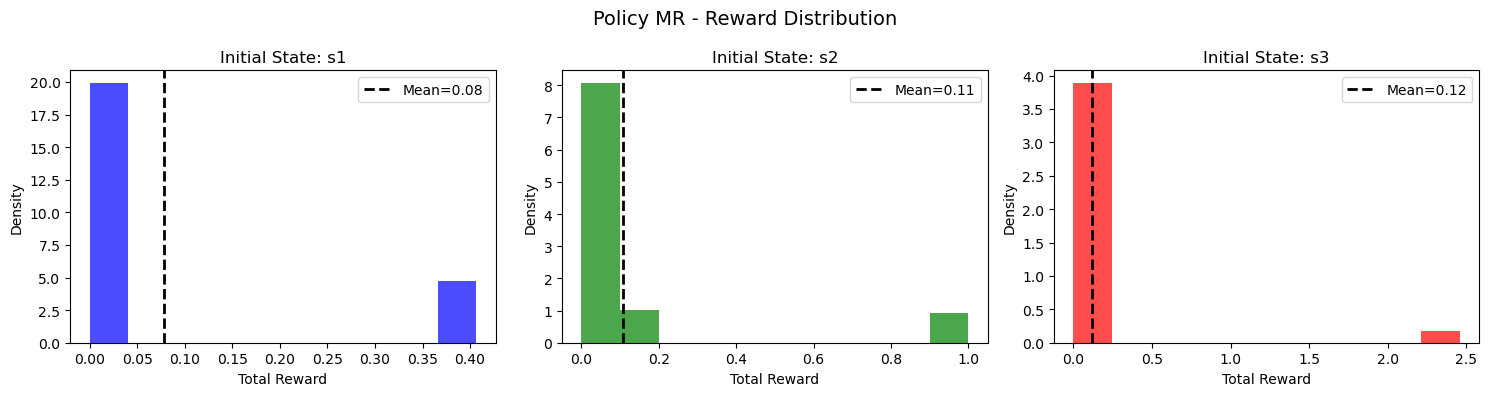

In [78]:
import matplotlib.pyplot as plt

# 第一张图：policy_MD
fig1, axes1 = plt.subplots(1, 3, figsize=(15, 4))
states = ['s1', 's2', 's3']
colors = ['blue', 'green', 'red']

for k in range(3):
    axes1[k].hist(reward_MD[k], bins=10, density=True, alpha=0.7, color=colors[k])
    axes1[k].axvline(E_policy_MD[k], color='black', linestyle='--', linewidth=2, label=f'Mean={E_policy_MD[k]:.2f}')
    axes1[k].set_title(f'Initial State: {states[k]}')
    axes1[k].set_xlabel('Total Reward')
    axes1[k].set_ylabel('Density')
    axes1[k].legend()

fig1.suptitle('Policy MD - Reward Distribution', fontsize=14)
plt.tight_layout()
plt.savefig('policy_MD_reward_distribution.png')
plt.show()

# 第二张图：policy_MR
fig2, axes2 = plt.subplots(1, 3, figsize=(15, 4))

for k in range(3):
    axes2[k].hist(reward_MR[k], bins=10, density=True, alpha=0.7, color=colors[k])
    axes2[k].axvline(E_policy_MR[k], color='black', linestyle='--', linewidth=2, label=f'Mean={E_policy_MR[k]:.2f}')
    axes2[k].set_title(f'Initial State: {states[k]}')
    axes2[k].set_xlabel('Total Reward')
    axes2[k].set_ylabel('Density')
    axes2[k].legend()

fig2.suptitle('Policy MR - Reward Distribution', fontsize=14)
plt.tight_layout()
plt.savefig('policy_MR_reward_distribution.png')
plt.show()

In [79]:
for name, reward in [('MD(π)', reward_MD), ('MR(π\')', reward_MR)]:
    print(f"\n=== {name} ===")
    for k, s in enumerate(['s1','s2','s3']):
        std = np.std(reward[k])          # 标准差
        p95 = np.percentile(reward[k], 95)  # 第95百分位
        mean = np.mean(reward[k])
        print(f"{s}: mean={mean:.2f}, std={std:.2f}, 95th percentile={p95:.2f}")


=== MD(π) ===
s1: mean=0.00, std=0.00, 95th percentile=0.00
s2: mean=0.25, std=0.43, 95th percentile=1.00
s3: mean=0.41, std=0.92, 95th percentile=2.46

=== MR(π') ===
s1: mean=0.08, std=0.16, 95th percentile=0.41
s2: mean=0.11, std=0.29, 95th percentile=1.00
s3: mean=0.12, std=0.51, 95th percentile=0.07
